# Modelos DSGE: aproximación de primer y segundo orden (Schmitt-Grohé & Uribe) — réplica en Python

Este notebook replica en Python el código MATLAB de la carpeta `Modelos` (toolbox de Stephanie Schmitt-Grohé y Martin Uribe).
Las ecuaciones de equilibrio del modelo se escriben como

$$E_t\, f(y_{t+1},y_t,x_{t+1},x_t)=0,$$

y la solución tiene la forma $x_{t+1}=h(x_t,\sigma)+\sigma\eta\,\varepsilon_{t+1}$, $\;y_t=g(x_t,\sigma)$.
Se aproximan $g$ y $h$ alrededor del estado estacionario no estocástico.

**Correspondencia MATLAB → Python**

| Carpeta / archivo MATLAB | Python en este notebook |
|---|---|
| `0.1 gx_hx.m` | `gx_hx` (QZ ordenada con `scipy.linalg.ordqz`) |
| `0.2 gss_hss.m`, `gxx_hxx*.m` | `gss_hss`, `gxx_hxx` |
| `0.3 anal_deriv.m`, `num_eval.m` | `anal_deriv` (SymPy), `num_eval` (`lambdify`) |
| `0.4 simu_2nd.m` | `simu_2nd` |
| `0.5 anal_deriv_print2f.m` | `anal_deriv_print2f` (devuelve una función numérica compilada en vez de escribir un `.m`) |
| `0.6 mom.m`, `0.7 unconditional_mean.m` | `mom`, `unconditional_mean` |
| `ir.m` | `ir` |
| `0.9–0.11` Ejemplos 1–3 | secciones 1–3 |
| `1.`–`8.` Modelos | secciones 4–11 |

**Notas sobre archivos que no están en la carpeta MATLAB**: `gxx_hxx.m` (solo aparece un `.html` que lo menciona), `ir.m`,
`find_interest_rate_ss.m` y los programas de Iskrev (`iskrev_*.m`) no están en el repositorio. `gxx_hxx` e `ir` se implementaron
desde las fórmulas de Schmitt-Grohé y Uribe (2004); el test de identificación de Iskrev no se replicó porque no hay código fuente.

Convención: variables en logaritmos salvo que se indique lo contrario (igual que en el código original); `p` al final = variable de $t+1$.

In [1]:
import numpy as np
import sympy as sp
import scipy.linalg as sla
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

np.set_printoptions(precision=6, suppress=True, linewidth=140)
pd.options.display.float_format = '{:,.4f}'.format
plt.rcParams['figure.figsize'] = (10, 7)

## 0. Herramientas generales
### 0.3 Derivadas analíticas (`anal_deriv`) y evaluación numérica (`num_eval`)
Los tensores se guardan como arreglos de NumPy de objetos SymPy con índices `[i, a, b]`
(ecuación, primera variable de derivación, segunda variable), igual que los `reshape(jacobian(...), n, na, nb)` de MATLAB.

In [2]:
def log_subs(f, variables):
    # f(vars) -> f(exp(vars)): permite escribir el modelo en niveles y aproximar en logs
    return sp.Matrix(f).subs({v: sp.exp(v) for v in variables}, simultaneous=True)


def _to_obj(M):
    return np.array(sp.Matrix(M).tolist(), dtype=object)


def _d2(F, v):
    # derivada de cada elemento de F (n x m) respecto de cada variable en v -> (n, m, len(v))
    out = np.empty(F.shape + (len(v),), dtype=object)
    for idx in np.ndindex(*F.shape):
        for k, vk in enumerate(v):
            out[idx + (k,)] = sp.diff(F[idx], vk)
    return out


def anal_deriv(f, x, y, xp, yp, approx=2):
    # Derivadas analiticas de primer (y segundo si approx=2) orden de f respecto de x, y, xp, yp
    f = sp.Matrix(f)
    x, y, xp, yp = [list(v) for v in (x, y, xp, yp)]
    d = {'fx': _to_obj(f.jacobian(x)), 'fxp': _to_obj(f.jacobian(xp)),
         'fy': _to_obj(f.jacobian(y)), 'fyp': _to_obj(f.jacobian(yp))}
    if approx == 2:
        fx, fxp, fy, fyp = d['fx'], d['fxp'], d['fy'], d['fyp']
        d.update({
            'fypyp': _d2(fyp, yp), 'fypy': _d2(fyp, y), 'fypxp': _d2(fyp, xp), 'fypx': _d2(fyp, x),
            'fyyp': _d2(fy, yp),   'fyy': _d2(fy, y),   'fyxp': _d2(fy, xp),   'fyx': _d2(fy, x),
            'fxpyp': _d2(fxp, yp), 'fxpy': _d2(fxp, y), 'fxpxp': _d2(fxp, xp), 'fxpx': _d2(fxp, x),
            'fxyp': _d2(fx, yp),   'fxy': _d2(fx, y),   'fxxp': _d2(fx, xp),   'fxx': _d2(fx, x)})
    return d


SECOND = ['fypyp','fypy','fypxp','fypx','fyyp','fyy','fyxp','fyx','fxpyp','fxpy','fxpxp','fxpx','fxyp','fxy','fxxp','fxx']


def num_eval(d, f, values, extra=None):
    # Evalua numericamente f y sus derivadas. values: {simbolo: numero} (parametros y estado estacionario)
    # extra: dict de arreglos simbolicos adicionales (p.ej. ETASHOCK)
    syms = list(values.keys())
    vals = [values[s] for s in syms]
    if any(np.iscomplexobj(v) and np.imag(v) != 0 for v in vals):
        vals = [complex(v) for v in vals]
    items = list(d.items()) + [('f', _to_obj(f))] + list((extra or {}).items())
    out, maximag = {}, 0.0
    for name, arr in items:
        arr = np.asarray(arr, dtype=object)
        fn = sp.lambdify(syms, arr.ravel().tolist(), modules='numpy')
        res = np.array(fn(*vals), dtype=complex).reshape(arr.shape)
        if res.size:
            maximag = max(maximag, np.abs(res.imag).max())
        out[name] = res.real if np.abs(res.imag).max(initial=0) < 1e-8 else res
    if maximag > 0:
        print(f'[num_eval] max |parte imaginaria| descartada: {maximag:.2e}')
    return out


def make_values(ss, symtab):
    # empareja el diccionario de estado estacionario con los simbolos del modelo
    values = {symtab[k]: v for k, v in ss.items() if k in symtab}
    missing = [k for k in symtab if k not in ss]
    assert not missing, f'faltan valores para: {missing}'
    return values


def anal_deriv_print2f(d, f, symtab, extra=None):
    # Equivalente de anal_deriv_print2f.m: en MATLAB escribe un archivo *_num_eval.m; aqui devolvemos una funcion compilada
    def _num_eval(ss):
        return num_eval(d, f, make_values(ss, symtab), extra)
    return _num_eval

### 0.1 Aproximación de primer orden (`gx_hx.m`)
Versión de Klein (2000) vía descomposición QZ ordenada. Con `scipy.linalg.ordqz` se ordenan los autovalores estables
(|t_ii| < stake·|s_ii|) en la esquina superior izquierda. `exitflag`: 0 no hay solución, 1 solución única, 2 indeterminación, 3 $z_{11}$ no invertible.

In [3]:
def gx_hx(fy, fx, fyp, fxp, stake=1.0):
    fy, fx, fyp, fxp = [np.atleast_2d(np.asarray(m, dtype=float)) for m in (fy, fx, fyp, fxp)]
    exitflag = 1
    A = np.hstack([-fxp, -fyp])
    B = np.hstack([fx, fy])
    NK = fx.shape[1]

    # Schur generalizada compleja, estables (|t|<stake*|s|) primero. scipy: A = Q AA Z^H, B = Q BB Z^H
    s, t, alpha, beta, q, z = sla.ordqz(A, B, sort=lambda a, b: np.abs(b) < stake * np.abs(a), output='complex')
    nk = int(np.sum(np.abs(np.diag(t)) < stake * np.abs(np.diag(s))))

    z21 = z[nk:, :nk]
    z11 = z[:nk, :nk]
    s11 = s[:nk, :nk]
    t11 = t[:nk, :nk]

    if nk > NK:
        print('Advertencia: el equilibrio es localmente indeterminado'); exitflag = 2
    elif nk < NK:
        print('Advertencia: no existe equilibrio local'); exitflag = 0
    if np.linalg.matrix_rank(z11) < nk:
        print('Advertencia: condicion de invertibilidad violada'); exitflag = 3

    z11i = np.linalg.inv(z11)
    gx = np.real(z21 @ z11i)
    hx = np.real(z11 @ np.linalg.solve(s11, t11) @ z11i)
    return gx, hx, exitflag

### 0.2 Aproximación de segundo orden (`gxx_hxx`, `gss_hss.m`)
`gxx_hxx` no está en la carpeta MATLAB; se obtiene diferenciando dos veces $F(x,\sigma)=E f(g(h(x,\sigma)+\sigma\eta\varepsilon,\sigma),g(x,\sigma),h(x,\sigma)+\sigma\eta\varepsilon,x)=0$
respecto de $x$ y resolviendo el sistema lineal en $(g_{xx},h_{xx})$ (Schmitt-Grohé y Uribe, 2004).

In [4]:
def gxx_hxx(fx, fxp, fy, fyp, fypyp, fypy, fypxp, fypx, fyyp, fyy, fyxp, fyx,
            fxpyp, fxpy, fxpxp, fxpx, fxyp, fxy, fxxp, fxx, hx, gx):
    n, nx = fx.shape
    ny = fy.shape[1]
    g, h, I = gx, hx, np.eye(nx)
    E = np.einsum

    # bloques: derivada de cada gradiente de f respecto de x_j, a lo largo de la solucion
    Ayp = E('iab,bd,dj->iaj', fypyp, g, h) + E('iab,bj->iaj', fypy, g) + E('iab,bj->iaj', fypxp, h) + fypx
    Ay  = E('iab,bd,dj->iaj', fyyp, g, h)  + E('iab,bj->iaj', fyy, g)  + E('iab,bj->iaj', fyxp, h)  + fyx
    Axp = E('iab,bd,dj->iaj', fxpyp, g, h) + E('iab,bj->iaj', fxpy, g) + E('iab,bj->iaj', fxpxp, h) + fxpx
    Ax  = E('iab,bd,dj->iaj', fxyp, g, h)  + E('iab,bj->iaj', fxy, g)  + E('iab,bj->iaj', fxxp, h)  + fxx

    # terminos que no involucran las incognitas gxx, hxx -> R[i,j,k]
    R = (E('iaj,ac,ck->ijk', Ayp, g, h) + E('iaj,ak->ijk', Ay, g)
         + E('iaj,ak->ijk', Axp, h) + E('ikj->ijk', Ax))

    # coeficientes de las incognitas: u = [gxx[a,c,d] ; hxx[a,c,d]]
    Mg = E('ia,cj,dk->ijkacd', fyp, h, h) + E('ia,cj,dk->ijkacd', fy, I, I)
    Mh = E('ia,cj,dk->ijkacd', fyp @ g, I, I) + E('ia,cj,dk->ijkacd', fxp, I, I)
    M = np.hstack([Mg.reshape(n * nx * nx, ny * nx * nx), Mh.reshape(n * nx * nx, nx * nx * nx)])
    u = np.linalg.solve(M, -R.reshape(-1))
    gxx = u[:ny * nx * nx].reshape(ny, nx, nx)
    hxx = u[ny * nx * nx:].reshape(nx, nx, nx)
    return gxx, hxx


def gss_hss(fx, fxp, fy, fyp, fypyp, fypy, fypxp, fypx, fyyp, fyy, fyxp, fyx,
            fxpyp, fxpy, fxpxp, fxpx, fxyp, fxy, fxxp, fxx, hx, gx, gxx, eta):
    nx = hx.shape[0]
    ny = gx.shape[0]
    n = nx + ny
    eta = np.atleast_2d(eta)
    Qh = np.zeros((n, nx)); Qg = np.zeros((n, ny)); q = np.zeros(n)
    ge = gx @ eta                                    # ny x ne
    for i in range(n):
        Qh[i, :] = fyp[i, :] @ gx                    # primer termino
        q[i] = np.trace((fypyp[i] @ ge).T @ ge)      # segundo
        q[i] += np.trace((fypxp[i] @ eta).T @ ge)    # tercero
        M = (fyp[i, :] @ gxx.reshape(ny, nx * nx)).reshape(nx, nx)   # cuarto
        q[i] += np.trace((M @ eta).T @ eta)
        Qg[i, :] = fyp[i, :] + fy[i, :]              # quinto y sexto
        Qh[i, :] += fxp[i, :]                        # septimo
        q[i] += np.trace((fxpyp[i] @ ge).T @ eta)    # octavo
        q[i] += np.trace((fxpxp[i] @ eta).T @ eta)   # noveno
    x = -np.linalg.solve(np.hstack([Qg, Qh]), q)
    return x[:ny], x[ny:]

### 0.4 Simulación de segundo orden, 0.6 momentos incondicionales, 0.7 medias incondicionales e impulso–respuesta

In [5]:
def simu_2nd(gx, hx, gxx, hxx, gss, hss, eta, sig, x0, e):
    # xp = hx x + 1/2 hxx x x + 1/2 hss sig^2 + sig eta e ;  y = gx x + 1/2 gxx x x + 1/2 gss sig^2  (pruned)
    eta = np.atleast_2d(eta)
    T = e.shape[0] + 1
    nx, ny = hx.shape[0], gx.shape[0]
    x0 = np.asarray(x0, float).ravel()
    X = np.zeros((T, nx)); Y = np.zeros((T, ny))
    X[0] = x0
    xf, xs = x0.copy(), 0 * x0
    for t in range(T):
        y = np.array([gx[i] @ (xf + xs) + 0.5 * xf @ gxx[i] @ xf + 0.5 * gss[i] * sig**2 for i in range(ny)])
        Y[t] = y
        if t < T - 1:
            xoldf, xolds = xf.copy(), xs.copy()
            xf = np.array([hx[i] @ xoldf + sig * eta[i] @ e[t] for i in range(nx)])
            xs = np.array([hx[i] @ xolds + 0.5 * xoldf @ hxx[i] @ xoldf + 0.5 * hss[i] * sig**2 for i in range(nx)])
            X[t + 1] = xf + xs
    return Y, X


def mom(gx, hx, varshock, J=0, method=1):
    # Varianzas/covarianzas incondicionales: sigxJ = E[x(t) x(t+J)'], sigyJ = E[y(t) y(t+J)']
    # method=1: algoritmo de doubling; otro: metodo algebraico (Kronecker)
    nx = hx.shape[0]
    if method == 1:
        hx_old, sig_old, sigx_old = hx.copy(), varshock.copy(), np.eye(nx)
        dif, it = 0.1, 0
        while dif > 1e-25 and it < 200:
            sigx = hx_old @ sigx_old @ hx_old.T + sig_old
            dif = np.max(np.abs(sigx - sigx_old))
            sig_old = hx_old @ sig_old @ hx_old.T + sig_old
            hx_old = hx_old @ hx_old
            sigx_old = sigx
            it += 1
            if not np.isfinite(dif):
                print('mom: doubling no converge (raiz unitaria o explosiva en hx)'); break
    else:
        F = np.kron(hx, hx)
        sigx = np.linalg.solve(np.eye(F.shape[0]) - F, varshock.reshape(-1, order='F')).reshape(nx, nx, order='F')
    sigxJ = np.linalg.matrix_power(hx, -min(0, J)) @ sigx @ np.linalg.matrix_power(hx.T, max(0, J))
    sigyJ = np.real(gx @ sigxJ @ gx.T)
    return sigyJ, np.real(sigxJ)


def unconditional_mean(gx, hx, gxx, hxx, gss, hss, eta, sig):
    eta = np.atleast_2d(eta)
    nx, ny = hx.shape[0], gx.shape[0]
    _, var_cov_x = mom(gx, hx, sig**2 * (eta @ eta.T), 0)
    a = np.array([np.sum(var_cov_x * hxx[i]) + hss[i] * sig**2 for i in range(nx)])
    b = np.array([np.sum(var_cov_x * gxx[i]) + gss[i] * sig**2 for i in range(ny)])
    Ex = np.linalg.solve(np.eye(nx) - hx, a / 2)
    Ey = gx @ Ex + b / 2
    return Ey, Ex


def ir(gx, hx, x0, T):
    # impulso-respuesta de primer orden: x(t+1) = hx x(t), y(t) = gx x(t)  (T filas)
    x = np.asarray(x0, float).ravel().copy()
    IRx = np.zeros((T, x.size)); IRy = np.zeros((T, gx.shape[0]))
    for t in range(T):
        IRx[t] = x; IRy[t] = gx @ x; x = hx @ x
    return IRy, IRy, IRx


def second_order(nd, eta):
    # atajo: gx,hx,gxx,hxx,gss,hss a partir del dict de derivadas numericas
    gx, hx, flag = gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'])
    args = [nd[k] for k in ['fx','fxp','fy','fyp'] + SECOND]
    gxx, hxx = gxx_hxx(*args, hx, gx)
    gss, hss = gss_hss(*args, hx, gx, gxx, eta)
    return gx, hx, gxx, hxx, gss, hss, flag

## 1. Ejemplo 1: modelo neoclásico de crecimiento (`9. Example 1`)
$y=\log c$, $x=[\log k,\ \log A]$. Con $\delta=1$ y utilidad CRRA existe solución cerrada
$\log c = \log(1-\alpha\beta)+\alpha\log k+\log A$, $\log k' = \log(\alpha\beta)+\alpha\log k+\log A$, que sirve para validar el código.

In [6]:
def neoclassical_model_ss():
    BETTA = 0.95; DELTA = 1; ALFA = 0.3; RHO = 0; SIG = 2
    eta = np.array([[0.0], [1.0]])
    A = 1.0
    K = ((1 / BETTA + DELTA - 1) / ALFA) ** (1 / (ALFA - 1))
    C = A * K ** ALFA - DELTA * K
    a, k, c = np.log(A), np.log(K), np.log(C)
    ss = dict(SIG=SIG, DELTA=DELTA, ALFA=ALFA, BETTA=BETTA, RHO=RHO, c=c, cp=c, k=k, kp=k, a=a, ap=a)
    return ss, eta


def neoclassical_model():
    SIG, DELTA, ALFA, BETTA, RHO = sp.symbols('SIG DELTA ALFA BETTA RHO', real=True)
    c, cp, k, kp, a, ap = sp.symbols('c cp k kp a ap', real=True)
    f1 = c + kp - (1 - DELTA) * k - a * k**ALFA
    f2 = c**(-SIG) - BETTA * cp**(-SIG) * (ap * ALFA * kp**(ALFA - 1) + 1 - DELTA)
    f3 = sp.log(ap) - RHO * sp.log(a)
    f = sp.Matrix([f1, f2, f3])
    x, y, xp, yp = [k, a], [c], [kp, ap], [cp]
    f = log_subs(f, x + y + xp + yp)             # f en funcion de los logaritmos
    d = anal_deriv(f, x, y, xp, yp, 2)
    symtab = {str(s): s for s in (SIG, DELTA, ALFA, BETTA, RHO, c, cp, k, kp, a, ap)}
    return d, f, symtab

In [7]:
d, f, symtab = neoclassical_model()
ss, eta = neoclassical_model_ss()
nd = num_eval(d, f, make_values(ss, symtab))

gx, hx, gxx, hxx, gss, hss, flag = second_order(nd, eta)
print('exitflag =', flag)
print('gx =\n', gx, '\nhx =\n', hx)
print('gxx =\n', gxx, '\nhxx =\n', hxx)
print('gss =', gss, ' hss =', hss)

exitflag = 1
gx =
 [[0.252523 0.841743]] 
hx =
 [[ 0.419109  1.397031]
 [ 0.       -0.      ]]
gxx =
 [[[-0.005118 -0.01706 ]
  [-0.01706  -0.056866]]] 
hxx =
 [[[-0.007002 -0.023341]
  [-0.023341 -0.077802]]

 [[ 0.        0.      ]
  [ 0.        0.      ]]]
gss = [-0.192144]  hss = [ 0.482044 -0.      ]


**Validación.** (i) Con $\sigma_{CRRA}=1$ (utilidad logarítmica) existe solución cerrada y los coeficientes de segundo orden deben ser cero.
(ii) Con $\sigma_{CRRA}=2$ (el valor del archivo), el residuo de la ecuación de Euler evaluado sobre la política aproximada debe caer a tasa $t^2$ (primer orden) y $t^3$ (segundo orden) cuando se escalan los estados y $\sigma$ por $t$.

In [8]:
# (i) solucion cerrada con SIG = 1: gx=[ALFA,1], hx=[[ALFA,1],[0,0]], gxx = hxx = gss = hss = 0
nd1 = num_eval(d, f, make_values(dict(ss, SIG=1), symtab))
g1, h1, g1xx, h1xx, g1ss, h1ss, _ = second_order(nd1, eta)
A_ = ss['ALFA']
print('SIG=1, error vs solucion cerrada:', max(np.abs(g1 - [[A_, 1]]).max(), np.abs(h1 - [[A_, 1], [0, 0]]).max(),
      np.abs(g1xx).max(), np.abs(h1xx).max(), np.abs(g1ss).max(), np.abs(h1ss).max()))

# (ii) residuo de Euler de la politica aproximada (SIG = 2, RHO = 0.5), esperanza por Gauss-Hermite
nd2 = num_eval(d, f, make_values(dict(ss, RHO=0.5), symtab))
G, H, GXX, HXX, GSS, HSS, _ = second_order(nd2, eta)
SIG_, AL_, BE_, DE_ = ss['SIG'], ss['ALFA'], ss['BETTA'], ss['DELTA']
zq, wq = np.polynomial.hermite_e.hermegauss(40); wq = wq / wq.sum()
xbar = np.array([ss['k'], ss['a']])

def policy(x, sg, order):
    c = ss['c'] + G[0] @ x
    h = xbar + H @ x
    if order == 2:
        c += 0.5 * x @ GXX[0] @ x + 0.5 * GSS[0] * sg**2
        h = h + 0.5 * np.array([x @ HXX[i] @ x for i in range(2)]) + 0.5 * HSS * sg**2
    return c, h

def euler_resid(x, sg, order):
    c, h = policy(x, sg, order)
    rhs = 0.0
    for zi, wi in zip(zq, wq):
        xn = np.array([h[0] - ss['k'], h[1] - ss['a'] + sg * zi * eta[1, 0]])
        cn, _ = policy(xn, sg, order)
        rhs += wi * np.exp(cn)**(-SIG_) * (AL_ * np.exp(xn[1] + ss['a']) * np.exp(h[0])**(AL_ - 1) + 1 - DE_)
    return abs(np.exp(c)**(-SIG_) - BE_ * rhs)

rows = []
for order in (1, 2):
    r = [euler_resid(t * np.array([0.3, 0.2]), t * 0.1, order) for t in (1, .5, .25)]
    rows.append(['1er orden' if order == 1 else '2do orden'] + [f'{v:.2e}' for v in r] + [f'{r[0]/r[1]:.1f}', f'{r[1]/r[2]:.1f}'])
display(pd.DataFrame(rows, columns=['aprox.', 't=1', 't=1/2', 't=1/4', 'ratio 1->1/2', 'ratio 1/2->1/4']).set_index('aprox.'))
print('Ratios ~4 => error de orden t^2 (1er orden); ratios ~8 => error de orden t^3 (2do orden).')

SIG=1, error vs solucion cerrada: 6.132210505711185e-16


,t=1,t=1/2,t=1/4,ratio 1->1/2,ratio 1/2->1/4
aprox.,,,,,
1er orden,1.24e-02,4.02e-03,1.15e-03,3.1,3.5
2do orden,2.60e-04,4.25e-05,6.08e-06,6.1,7.0


Ratios ~4 => error de orden t^2 (1er orden); ratios ~8 => error de orden t^3 (2do orden).


## 2. Ejemplo 2: dos países con mercados completos (`10. Example 2`, Kim y Kim 2003)

In [9]:
def kim_ss():
    GAMA = 2; DELTA = 0.1; ALFA = 0.3; RHO = 0; BETTA = 0.95
    k1 = ((BETTA**(-1) - 1 + DELTA) / ALFA) ** (1 / (ALFA - 1)); k2 = k1
    c = k1**ALFA - DELTA * k1
    a1 = 1; a2 = 1
    c, k1, k2, a1, a2 = [np.log(v) for v in (c, k1, k2, a1, a2)]
    return dict(GAMA=GAMA, DELTA=DELTA, ALFA=ALFA, RHO=RHO, BETTA=BETTA,
                c=c, cp=c, k1=k1, k1p=k1, k2=k2, k2p=k2, a1=a1, a1p=a1, a2=a2, a2p=a2)


def kim_model(approx=2):
    GAMA, DELTA, ALFA, RHO, BETTA = sp.symbols('GAMA DELTA ALFA RHO BETTA', real=True)
    c, cp, k1, k1p, k2, k2p, a1, a1p, a2, a2p = sp.symbols('c cp k1 k1p k2 k2p a1 a1p a2 a2p', real=True)
    e1 = c**(-GAMA) - BETTA * cp**(-GAMA) * (ALFA * a1p * k1p**(ALFA - 1) + 1 - DELTA)
    e2 = c**(-GAMA) - BETTA * cp**(-GAMA) * (ALFA * a2p * k2p**(ALFA - 1) + 1 - DELTA)
    e3 = 2 * c + k1p - (1 - DELTA) * k1 + k2p - (1 - DELTA) * k2 - a1 * k1**ALFA - a2 * k2**ALFA
    e4 = sp.log(a1p) - RHO * sp.log(a1)
    e5 = sp.log(a2p) - RHO * sp.log(a2)
    f = sp.Matrix([e1, e2, e3, e4, e5])
    x, y, xp, yp = [k1, k2, a1, a2], [c], [k1p, k2p, a1p, a2p], [cp]
    f = log_subs(f, x + y + xp + yp)
    d = anal_deriv(f, x, y, xp, yp, approx)
    symtab = {str(s): s for s in (GAMA, DELTA, ALFA, RHO, BETTA, c, cp, k1, k1p, k2, k2p, a1, a1p, a2, a2p)}
    return d, f, symtab


d, f, symtab = kim_model()
nd = num_eval(d, f, make_values(kim_ss(), symtab))
eta = np.array([[0, 0], [0, 0], [1, 0], [0, 1]], dtype=float)
gx, hx, gxx, hxx, gss, hss, flag = second_order(nd, eta)
print('exitflag =', flag)
print('gx =\n', gx, '\nhx =\n', hx)
print('gss =', gss, '\nhss =', hss)

exitflag = 1
gx =
 [[0.201303 0.201303 0.097297 0.097297]] 
hx =
 [[0.444029 0.444029 0.214614 0.214614]
 [0.444029 0.444029 0.214614 0.214614]
 [0.       0.       0.       0.      ]
 [0.       0.       0.       0.      ]]
gss = [0.406155] 
hss = [-0.166025 -0.166025 -0.       -0.      ]


## 3. Ejemplo 3: modelo de precios de activos de Burnside (`11. Example 3`)
Estado $a$ (crecimiento del dividendo, en niveles) y control $p$ (cociente precio/dividendo). Aquí no se toman logaritmos.
Además de replicar `asset_run.m`, se simula con `simu_2nd`, se calcula la media incondicional y se compara contra una solución "exacta" (proyección con Gauss–Hermite).

In [10]:
def asset_ss():
    XBAR = 0.0179; RHO = -0.139; THETA = -1.5; BETTA = 0.95
    sig = 1.0
    eta = np.array([[0.0348]])
    p = BETTA * np.exp(THETA * XBAR) / (1 - BETTA * np.exp(THETA * XBAR))
    a = XBAR
    ss = dict(XBAR=XBAR, RHO=RHO, THETA=THETA, BETTA=BETTA, p=p, pp=p, a=a, ap=a)
    return ss, eta, sig


def asset_model(approx=2):
    XBAR, RHO, THETA, BETTA = sp.symbols('XBAR RHO THETA BETTA', real=True)
    p, pp, a, ap = sp.symbols('p pp a ap', real=True)
    e1 = -p + BETTA * (1 + pp) * sp.exp(THETA * ap)
    e2 = -ap + (1 - RHO) * XBAR + RHO * a
    f = sp.Matrix([e1, e2])
    d = anal_deriv(f, [a], [p], [ap], [pp], approx)
    symtab = {str(s): s for s in (XBAR, RHO, THETA, BETTA, p, pp, a, ap)}
    return d, f, symtab


d, f, symtab = asset_model()
ss, eta, sig = asset_ss()
nd = num_eval(d, f, make_values(ss, symtab))
gx, hx, gxx, hxx, gss, hss, flag = second_order(nd, eta)
print('exitflag =', flag)
print('p_bar =', ss['p'])
print('gx =', gx, ' hx =', hx, ' gxx =', gxx.ravel(), ' hxx =', hxx.ravel())
print('gss =', gss, ' hss =', hss)

exitflag =

 1
p_bar = 12.30351462782001
gx = [[2.273075]]  hx = [[-0.139]]  gxx = [0.420525]  hxx = [0.]
gss = [0.350661]  hss = [0.]


In [11]:
# --- simu_2nd y unconditional_mean ---
rng = np.random.default_rng(0)
T = 200_000
e = rng.standard_normal((T, 1))
Y, X = simu_2nd(gx, hx, gxx, hxx, gss, hss, eta, sig, np.zeros(1), e)
Ey, Ex = unconditional_mean(gx, hx, gxx, hxx, gss, hss, eta, sig)
print('Media incondicional teorica  E[y], E[x]:', Ey, Ex)
print('Media simulada               E[y], E[x]:', Y[1000:].mean(0), X[1000:].mean(0))

# --- chequeo contra solucion "exacta" p(a) = BETTA * E[(1+p(a')) exp(THETA a')] (Gauss-Hermite + Chebyshev) ---
XBAR, RHO, THETA, BETTA = ss['XBAR'], ss['RHO'], ss['THETA'], ss['BETTA']
s_a = eta[0, 0]
nodes, w = np.polynomial.hermite_e.hermegauss(20); w = w / w.sum()
lo, hi = XBAR - 0.3, XBAR + 0.3
deg = 16
cheb = np.cos(np.pi * (np.arange(deg + 1) + 0.5) / (deg + 1))
agrid = XBAR + (hi - lo) / 2 * cheb
pc = np.full(deg + 1, ss['p'])
for _ in range(1000):
    poly = np.polynomial.chebyshev.Chebyshev.fit(agrid, pc, deg, domain=[lo, hi])
    an = (1 - RHO) * XBAR + RHO * agrid[:, None] + s_a * nodes[None, :]
    new = BETTA * (w[None, :] * (1 + poly(an)) * np.exp(THETA * an)).sum(1)
    if np.abs(new - pc).max() < 1e-14: break
    pc = new
poly = np.polynomial.chebyshev.Chebyshev.fit(agrid, pc, deg, domain=[lo, hi])
dev = np.array([-0.04, -0.02, 0.0, 0.02, 0.04])
a_pts = XBAR + dev
p2 = ss['p'] + gx[0, 0] * dev + 0.5 * gxx[0, 0, 0] * dev**2 + 0.5 * gss[0] * sig**2
p1 = ss['p'] + gx[0, 0] * dev
print(pd.DataFrame({'a': a_pts, 'exacto': poly(a_pts), '2do orden': p2, '1er orden': p1}))

Media incondicional teorica  E[y], E[x]: [0.17559] [0.]
Media simulada               E[y], E[x]: [0.175617] [0.000011]
        a  exacto  2do orden  1er orden
0 -0.0221 12.3894    12.3883    12.2126
1 -0.0021 12.4352    12.4335    12.2581
2  0.0179 12.4812    12.4788    12.3035
3  0.0379 12.5274    12.5244    12.3490
4  0.0579 12.5738    12.5701    12.3944


## Utilidades comunes para los modelos de economía abierta (4–11)
Las carpetas 1, 2, 3, 5 y 8 comparten el mismo `run`: tabla de segundos momentos (desvío estándar en %, autocorrelación, correlación con el producto)
e impulso–respuesta a un shock de productividad. Desvío del shock de productividad: $0.0129$ (Tabla 6 de Mendoza, AER 1991).

In [12]:
NAMES6 = ['y', 'c', 'i', 'h', 'tb/y', 'ca/y']


def log_ss(ss, names):
    # aplica log a las variables indicadas (y a su version con p); log complejo si el valor es negativo (igual que MATLAB)
    ss = dict(ss)
    for n in names:
        ss[n] = np.log(complex(ss[n])) if np.real(ss[n]) < 0 else np.log(ss[n])
        ss[n + 'p'] = ss[n]
    return ss


def plot_ir(IR, label):
    t = np.arange(IR.shape[0])
    fig, axs = plt.subplots(3, 2, figsize=(10, 8))
    for ax, j, ttl in zip(axs.ravel(), range(6),
                          ['Output', 'Consumption', 'Investment', 'Hours', 'Trade Balance / GDP', 'Current Account / GDP']):
        ax.plot(t, IR[:, j]); ax.set_title(ttl); ax.axhline(0, color='k', lw=.5)
    fig.suptitle(f'Impulso-respuesta a un shock de productividad: {label}')
    fig.tight_layout(); plt.show()


def run_mendoza(nd, label, T=10, moments=True, stake=1.0):
    # replica de mendoza91_run.m, deir_run.m, bac_run.m, py_run.m (y rw_run.m con moments=False)
    gx, hx, flag = gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'], stake)
    print(f'{label}: exitflag = {flag}; autovalores de hx =', np.round(np.linalg.eigvals(hx), 4))
    out = dict(gx=gx, hx=hx)
    if moments:
        varshock = np.zeros((hx.shape[0],) * 2)
        varshock[-1, -1] = 0.0129 ** 2
        var_y, var_x = mom(gx, hx, varshock, 0)
        var_y1, var_x1 = mom(gx, hx, varshock, 1)
        tab = np.column_stack([
            np.sqrt(np.diag(var_y[:6, :6])) * 100,
            np.diag(var_y1[:6, :6]) / np.diag(var_y[:6, :6]),
            var_y[:6, 0] / np.sqrt(np.diag(var_y[:6, :6])) / np.sqrt(var_y[0, 0])])
        out['table'] = pd.DataFrame(tab, index=NAMES6, columns=['std (%)', 'autocorr.', 'corr con y'])
        display(out['table'])
    x0 = np.zeros(hx.shape[0]); x0[-1] = 1
    IR, _, _ = ir(gx, hx, x0, T)
    plot_ir(IR, label)
    return out

## 4. Modelo 1: factor de descuento endógeno con internalización (`1. Endogenous Discount Factor Model`)
Pequeña economía abierta con $\beta(c,h)=(1+c-h^\omega/\omega)^{-\psi}$ (Schmitt-Grohé y Uribe, *Closing small open economy models*).
Estado $x=[k,d,a]$; control $y=[y,c,i,h,tb/y,ca/y,tb,\eta,\lambda,k_1]$. La balanza comercial, tb/y y ca/y entran en niveles (el $\log$ del modelo se cancela con la sustitución $\exp$); el resto en logs.
Orden de aproximación: 1.

Mendoza 1991 (1): exitflag = 1; autovalores de hx = [0.4855+0.j 0.9838+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.0655,0.6122,1.0000
c,2.3479,0.6988,0.9376
i,9.1002,0.0700,0.6581
h,2.1069,0.6122,1.0000
tb/y,1.5481,0.3268,-0.0122
ca/y,1.4600,0.3022,0.0263


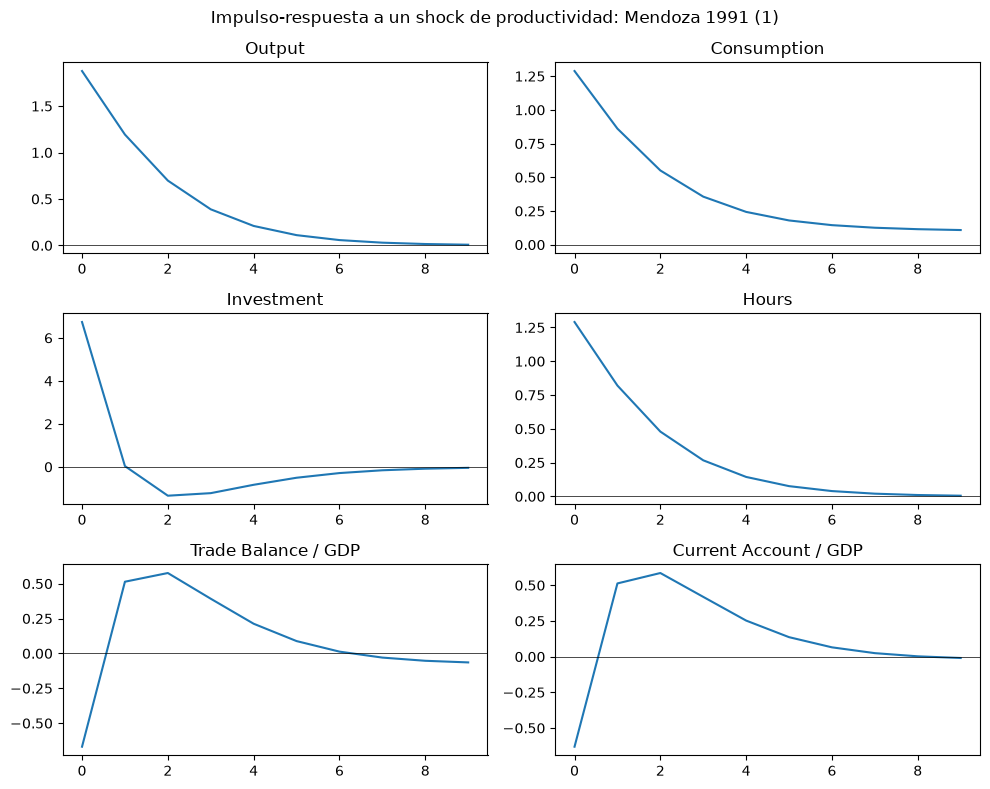

In [13]:
def mendoza91_ss():
    GAMA = 2; DELTA = 0.1; ALFA = 0.32; PSSI = 0.11135; RHO = 0.42; OMEGA = 1.455; PHI = 0.028; R = 0.04
    h_over_k = ((R + DELTA) / ALFA) ** (1 / (1 - ALFA))
    h = ((1 - ALFA) * (ALFA / (R + DELTA)) ** (ALFA / (1 - ALFA))) ** (1 / (OMEGA - 1))
    c = (1 + R) ** (1 / PSSI) + h**OMEGA / OMEGA - 1
    k = h / h_over_k
    iv = DELTA * k
    yy = k**ALFA * h**(1 - ALFA)
    tb = yy - c - iv
    d = tb / R
    U = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    Uc = (c - h**OMEGA / OMEGA) ** (-GAMA)
    tby = tb / yy
    cay = (-R * d + tb) / yy
    beta = 1 / (1 + R)
    betac = -PSSI * (1 + c - h**OMEGA / OMEGA) ** (-PSSI - 1)
    eta = -U / (1 - beta)
    la = Uc - eta * betac
    k1 = k
    a = 1.0
    ss = dict(GAMA=GAMA, DELTA=DELTA, ALFA=ALFA, PSSI=PSSI, RHO=RHO, OMEGA=OMEGA, PHI=PHI, R=R,
              c=c, h=h, k=k, k1=k1, d=d, iv=iv, tb=tb, eta=eta, la=la, yy=yy, a=a, tby=tby, cay=cay)
    ss = log_ss(ss, ['c', 'h', 'k', 'k1', 'la', 'eta', 'yy', 'iv', 'd', 'a'])   # logs (si eta<0 -> log complejo, como en MATLAB)
    for n in ['tb', 'tby', 'cay']:                                              # niveles
        ss[n + 'p'] = ss[n]
    return ss


def mendoza91_model(approx=1):
    GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R = sp.symbols('GAMA DELTA ALFA PSSI RHO OMEGA PHI R', real=True)
    names = 'c cp k kp k1 k1p a ap h hp d dp yy yyp iv ivp tb tbp la lap eta etap tby tbyp cay cayp'
    (c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap, eta, etap,
     tby, tbyp, cay, cayp) = sp.symbols(names, real=True)
    beta = (1 + c - h**OMEGA / OMEGA) ** (-PSSI)
    betap = (1 + cp - hp**OMEGA / OMEGA) ** (-PSSI)
    u = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    up = ((cp - hp**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    e1 = (1 + R) * d - sp.log(tb) - dp
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2
    e3 = -yy + a * k**ALFA * h**(1 - ALFA)
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la + beta * (1 + R) * lap
    e6 = -la + sp.diff(u, c) - eta * sp.diff(beta, c)
    e7 = -eta - up + etap * betap
    e8 = -sp.diff(u, h) + eta * sp.diff(beta, h) - la * sp.diff(output, h)
    e9 = -la * (1 + PHI * (kp - k)) + beta * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e10 = -k1 + kp
    e11 = -sp.log(ap) + RHO * sp.log(a)
    e12 = -sp.log(tby) + sp.log(tb) / yy
    e13 = -sp.log(cay) - R * d / yy + sp.log(tby)
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12, e13])
    x = [k, d, a]
    y = [yy, c, iv, h, tby, cay, tb, eta, la, k1]
    xp = [kp, dp, ap]
    yp = [yyp, cp, ivp, hp, tbyp, cayp, tbp, etap, lap, k1p]
    f = log_subs(f, x + y + xp + yp)
    dd = anal_deriv(f, x, y, xp, yp, approx)
    symtab = {str(s): s for s in [GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R] +
              [c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap, eta, etap, tby, tbyp, cay, cayp]}
    return dd, f, symtab


d, f, symtab = mendoza91_model()
nd = num_eval(d, f, make_values(mendoza91_ss(), symtab))
res1 = run_mendoza(nd, 'Mendoza 1991 (1)')

## 5. Modelo 2: factor de descuento endógeno sin internalización (`2. ...without Internalization`)
Igual que el modelo 1 pero los agentes no internalizan el efecto del consumo y las horas sobre $\beta$ (se elimina $\eta$; $\lambda=U_c$).

Sin internalizacion (2): exitflag = 1; autovalores de hx = [0.4855+0.j 0.9835+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.0655,0.6122,1.0000
c,2.3478,0.6986,0.9383
i,9.1002,0.0700,0.6581
h,2.1069,0.6122,1.0000
tb/y,1.5463,0.3250,-0.0130
ca/y,1.4594,0.3014,0.0254


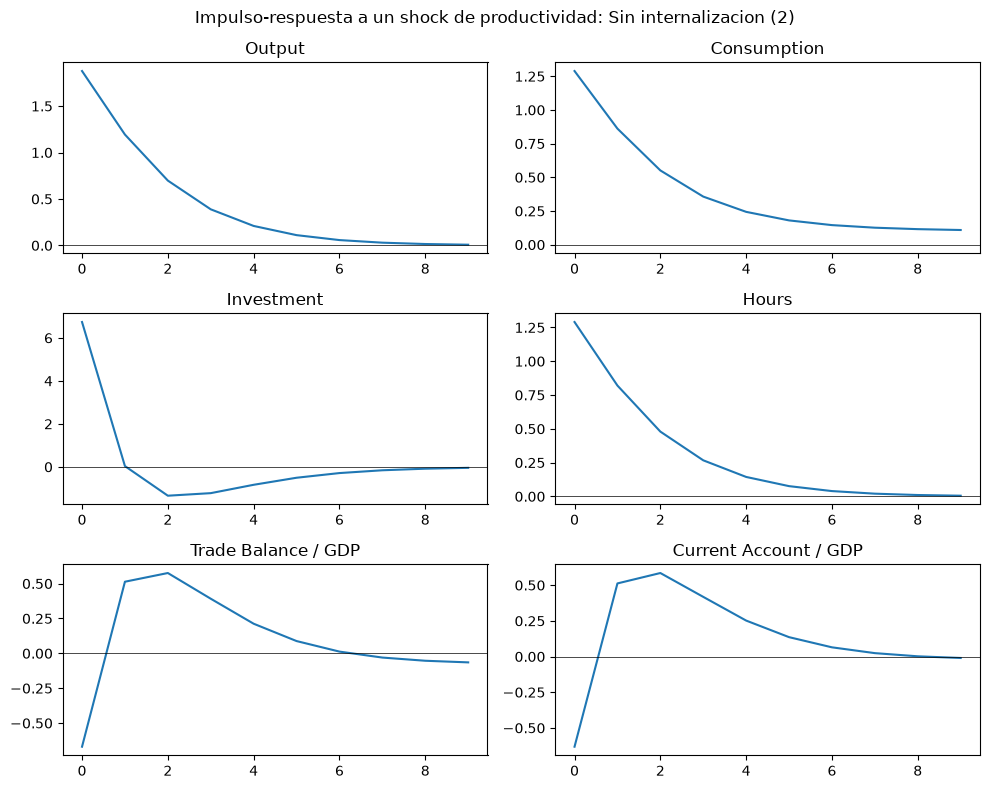

In [14]:
def mendoza91s_ss():
    ss = mendoza91_ss()
    GAMA, OMEGA, h, c = ss['GAMA'], ss['OMEGA'], np.exp(ss['h']), np.exp(ss['c'])
    Uc = (c - h**OMEGA / OMEGA) ** (-GAMA)
    ss['la'] = np.log(Uc); ss['lap'] = ss['la']
    ss.pop('eta'); ss.pop('etap')
    return ss


def mendoza91s_model(approx=1):
    GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R = sp.symbols('GAMA DELTA ALFA PSSI RHO OMEGA PHI R', real=True)
    (c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap,
     tby, tbyp, cay, cayp) = sp.symbols('c cp k kp k1 k1p a ap h hp d dp yy yyp iv ivp tb tbp la lap tby tbyp cay cayp', real=True)
    beta = (1 + c - h**OMEGA / OMEGA) ** (-PSSI)
    u = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    e1 = (1 + R) * d - sp.log(tb) - dp
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2
    e3 = -yy + a * k**ALFA * h**(1 - ALFA)
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la + beta * (1 + R) * lap
    e6 = -la + sp.diff(u, c)
    e8 = -sp.diff(u, h) - la * sp.diff(output, h)
    e9 = -la * (1 + PHI * (kp - k)) + beta * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e10 = -k1 + kp
    e11 = -sp.log(ap) + RHO * sp.log(a)
    e12 = -sp.log(tby) + sp.log(tb) / yy
    e13 = -sp.log(cay) - R * d / yy + sp.log(tby)
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e8, e9, e10, e11, e12, e13])
    x = [k, d, a]
    y = [yy, c, iv, h, tby, cay, tb, la, k1]
    xp = [kp, dp, ap]
    yp = [yyp, cp, ivp, hp, tbyp, cayp, tbp, lap, k1p]
    f = log_subs(f, x + y + xp + yp)
    dd = anal_deriv(f, x, y, xp, yp, approx)
    symtab = {str(s): s for s in [GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R] +
              [c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap, tby, tbyp, cay, cayp]}
    return dd, f, symtab


d, f, symtab = mendoza91s_model()
nd = num_eval(d, f, make_values(mendoza91s_ss(), symtab))
res2 = run_mendoza(nd, 'Sin internalizacion (2)')

## 6. Modelo 3: tasa de interés elástica a la deuda — deuda interna (`3. Internal Debt Elastic Interest Rate Model`)
La prima $p(d)=\psi\,(e^{d-\bar d}-1)$ depende de la deuda del propio hogar y éste la **internaliza** en su ecuación de Euler,
por eso aparece $(1+R+p')$ como retorno marginal y $R+p$ en $ca/y$. Los modelos 3, 5 y 7 comparten el mismo estado estacionario (`_open_econ_ss`).

DEIR (3): exitflag = 1; autovalores de hx = [0.4779+0.j 0.9967+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.0826,0.6170,1.0000
c,2.7064,0.7822,0.8441
i,9.0391,0.0686,0.6688
h,2.1186,0.6170,1.0000
tb/y,1.7782,0.5085,-0.0435
ca/y,1.4529,0.3220,0.0503


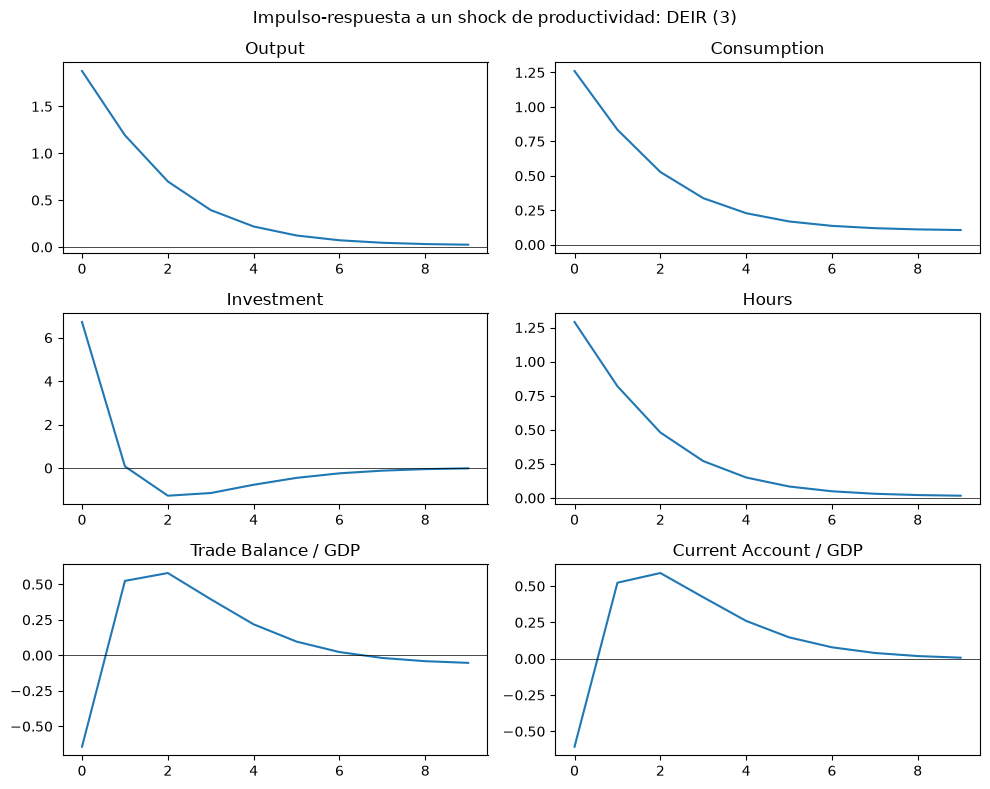

In [15]:
def _open_econ_ss(PSSI):
    # estado estacionario comun a deir, bac y rw (rw: sin PSSI)
    GAMA = 2; DELTA = 0.1; ALFA = 0.32; RHO = 0.42; OMEGA = 1.455; PHI = 0.028; R = 0.04
    DBAR = 0.74421765717098
    h_over_k = ((R + DELTA) / ALFA) ** (1 / (1 - ALFA))
    h = ((1 - ALFA) * (ALFA / (R + DELTA)) ** (ALFA / (1 - ALFA))) ** (1 / (OMEGA - 1))
    d = DBAR
    k = h / h_over_k
    iv = DELTA * k
    yy = k**ALFA * h**(1 - ALFA)
    tb = d * R
    c = yy - tb - iv
    tby = tb / yy
    cay = (-R * d + tb) / yy
    Uc = (c - h**OMEGA / OMEGA) ** (-GAMA)
    la = Uc
    k1 = k
    a = 1.0
    ss = dict(GAMA=GAMA, DELTA=DELTA, ALFA=ALFA, RHO=RHO, OMEGA=OMEGA, PHI=PHI, R=R, DBAR=DBAR,
              c=c, h=h, k=k, k1=k1, d=d, iv=iv, tb=tb, la=la, yy=yy, a=a, tby=tby, cay=cay)
    if PSSI is not None:
        ss['PSSI'] = PSSI
    ss = log_ss(ss, ['c', 'h', 'k', 'k1', 'la', 'yy', 'iv', 'd', 'a'])
    for n in ['tb', 'tby', 'cay']:
        ss[n + 'p'] = ss[n]
    return ss


def deir_ss():
    return _open_econ_ss(0.11135 / 150)


def _open_econ_symbols():
    (c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap,
     tby, tbyp, cay, cayp) = sp.symbols('c cp k kp k1 k1p a ap h hp d dp yy yyp iv ivp tb tbp la lap tby tbyp cay cayp', real=True)
    return dict(c=c, cp=cp, k=k, kp=kp, k1=k1, k1p=k1p, a=a, ap=ap, h=h, hp=hp, d=d, dp=dp, yy=yy, yyp=yyp, iv=iv, ivp=ivp,
                tb=tb, tbp=tbp, la=la, lap=lap, tby=tby, tbyp=tbyp, cay=cay, cayp=cayp)


def _finish_open_econ(S, params, f, approx):
    x = [S['k'], S['d'], S['a']]
    y = [S['yy'], S['c'], S['iv'], S['h'], S['tby'], S['cay'], S['tb'], S['la'], S['k1']]
    xp = [S['kp'], S['dp'], S['ap']]
    yp = [S['yyp'], S['cp'], S['ivp'], S['hp'], S['tbyp'], S['cayp'], S['tbp'], S['lap'], S['k1p']]
    f = log_subs(f, x + y + xp + yp)
    dd = anal_deriv(f, x, y, xp, yp, approx)
    symtab = {str(s): s for s in list(params) + list(S.values())}
    return dd, f, symtab


def deir_model(approx=1):
    GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R, DBAR = sp.symbols('GAMA DELTA ALFA PSSI RHO OMEGA PHI R DBAR', real=True)
    S = _open_econ_symbols()
    c, k, kp, k1, k1p, a, ap, h, hp, d, dp = [S[n] for n in 'c k kp k1 k1p a ap h hp d dp'.split()]
    yy, iv, tb, la, lap, tby, cay = [S[n] for n in 'yy iv tb la lap tby cay'.split()]
    u = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    p = PSSI * (sp.exp(d - DBAR) - 1)
    pp = PSSI * (sp.exp(dp - DBAR) - 1)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    e1 = (1 + R + p) * d - sp.log(tb) - dp
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2
    e3 = -yy + a * k**ALFA * h**(1 - ALFA)
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la * (1 + R) + (1 + R + pp) * lap
    e6 = -la + sp.diff(u, c)
    e7 = -sp.diff(u, h) - la * sp.diff(output, h)
    e8 = -la * (1 + PHI * (kp - k)) + 1 / (1 + R) * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e9 = -k1 + kp
    e10 = -sp.log(ap) + RHO * sp.log(a)
    e11 = -sp.log(tby) + sp.log(tb) / yy
    e12 = -sp.log(cay) - (R + p) * d / yy + sp.log(tby)
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12])
    return _finish_open_econ(S, [GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R, DBAR], f, approx)


d, f, symtab = deir_model()
nd = num_eval(d, f, make_values(deir_ss(), symtab))
res3 = run_mendoza(nd, 'DEIR (3)')

## 7. Modelo 4: tasa de interés elástica a la deuda — deuda externa (`4. External Debt Elastic Interest Rate Model`)
Aquí la tasa $r_t$ es una variable de estado que depende de la deuda agregada $d_t$ y el agente la toma como dada (EDEIR).
El modelo es de segundo orden en $k$ (aparece $k_{t+2}$), que se resuelve con la variable auxiliar `kfu` $=k_{t+1}$.
Los estados $d, r$ y las variables $tb, tb/y, ca, ca/y$ están en niveles; el resto en logs.
La función `anal_deriv_print2f` se usa como en MATLAB (ahí genera `edeir_num_eval.m`; aquí devuelve la función numérica).

exitflag = 1 | autovalores de hx: [0.9967+0.j 0.    +0.j 0.4779+0.j 0.42  +0.j]


,std,corr con y,autocorr.
y,0.0308,1.0000,0.6170
c,0.0271,0.8441,0.7822
i,0.0904,0.6688,0.0686
tb/y,0.0178,-0.0435,0.5085
ca/y,0.0145,0.0503,0.3220


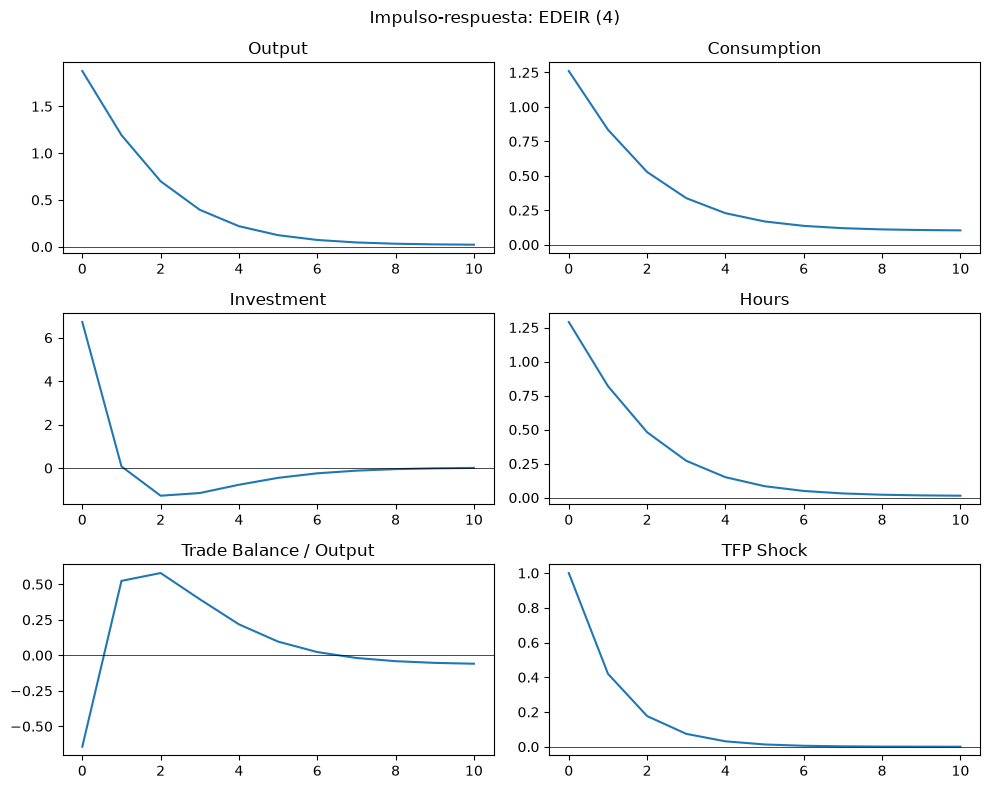

In [16]:
def edeir_ss():
    SIGG = 2; DELTA = 0.1; RSTAR = 0.04; ALFA = 0.32; OMEGA = 1.455
    DBAR = 0.74421765717098; PSSI = 0.11135 / 150; PHI = 0.028; RHO = 0.42; STD_EPS_A = 0.0129
    BETTA = 1 / (1 + RSTAR)
    r = RSTAR; d = DBAR
    KAPA = ((1 / BETTA - (1 - DELTA)) / ALFA) ** (1 / (ALFA - 1))
    h = ((1 - ALFA) * KAPA**ALFA) ** (1 / (OMEGA - 1))
    k = KAPA * h
    output = KAPA**ALFA * h
    c = output - DELTA * k - RSTAR * DBAR
    ivv = DELTA * k
    tb = output - ivv - c
    tby = tb / output
    ca = -r * d + tb
    cay = ca / output
    a = 1.0; tfp = a
    la = (c - h**OMEGA / OMEGA) ** (-SIGG)
    return dict(SIGG=SIGG, DELTA=DELTA, RSTAR=RSTAR, ALFA=ALFA, OMEGA=OMEGA, DBAR=DBAR, PSSI=PSSI, PHI=PHI, RHO=RHO,
                STD_EPS_A=STD_EPS_A, BETTA=BETTA, r=r, d=d, h=h, k=k, output=output, c=c, ivv=ivv, tb=tb, tby=tby, ca=ca,
                cay=cay, a=a, tfp=tfp, la=la, kfu=k)


def to_model_point(ss, log_names, level_names):
    # valores en el punto de evaluacion: logs para las variables en logs, niveles para el resto; la version 'p' = misma
    v = {}
    for n in log_names:
        v[n] = np.log(ss[n]); v[n + 'p'] = v[n]
    for n in level_names:
        v[n] = ss[n]; v[n + 'p'] = ss[n]
    return v


def edeir_model():
    (RSTAR, BETTA, DBAR, DELTA, ALFA, PHI, RHO, STD_EPS_A, SIGG, OMEGA, PSSI) = sp.symbols(
        'RSTAR BETTA DBAR DELTA ALFA PHI RHO STD_EPS_A SIGG OMEGA PSSI', real=True)
    names = 'c cp h hp d dp k kp kfu kfup la lap tb tbp ca cap ivv ivvp tby tbyp cay cayp r rp a ap output outputp tfp tfpp'
    (c, cp, h, hp, d, dp, k, kp, kfu, kfup, la, lap, tb, tbp, ca, cap, ivv, ivvp, tby, tbyp, cay, cayp,
     r, rp, a, ap, output, outputp, tfp, tfpp) = sp.symbols(names, real=True)
    e1 = -dp + (1 + r) * d + c + ivv + PHI / 2 * (kp - k)**2 - output
    e2 = -output + a * k**ALFA * h**(1 - ALFA)
    e3 = -la + (c - h**OMEGA / OMEGA) ** (-SIGG)
    e4 = -h**(OMEGA - 1) + (1 - ALFA) * a * (k / h)**ALFA
    e5 = -la + BETTA * (1 + rp) * lap
    e6 = -la * (1 + PHI * (kp - k)) + BETTA * lap * (1 - DELTA + ALFA * ap * (kp / hp)**(ALFA - 1) + PHI * (kfup - kp))
    e7 = -rp + RSTAR + PSSI * (sp.exp(dp - DBAR) - 1)
    e8 = -ivv + kp - (1 - DELTA) * k
    e9 = -tb + output - c - ivv
    e10 = -tby + tb / output
    e11 = -ca - dp + d
    e12 = -cay + ca / output
    e13 = -sp.log(ap) + RHO * sp.log(a)
    e14 = -kfu + kp
    e15 = -tfp + a
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12, e13, e14, e15])

    states_in_logs, states_in_logsp = [k, a], [kp, ap]
    statevar, statevarp = [d, r] + states_in_logs, [dp, rp] + states_in_logsp
    controls_in_logs = [c, ivv, output, h, la, kfu, tfp]
    controls_in_logsp = [cp, ivvp, outputp, hp, lap, kfup, tfpp]
    controlvar = controls_in_logs + [tb, tby, ca, cay]
    controlvarp = controls_in_logsp + [tbp, tbyp, cap, cayp]
    variables_in_logs = states_in_logs + controls_in_logs + states_in_logsp + controls_in_logsp
    f = log_subs(f, variables_in_logs)
    dd = anal_deriv(f, statevar, controlvar, statevarp, controlvarp, 1)

    ns = len(statevar)
    ETASHOCK = sp.zeros(ns, 1); ETASHOCK[ns - 1] = STD_EPS_A
    symtab = {str(s): s for s in (RSTAR, BETTA, DBAR, DELTA, ALFA, PHI, RHO, STD_EPS_A, SIGG, OMEGA, PSSI,
              c, cp, h, hp, d, dp, k, kp, kfu, kfup, la, lap, tb, tbp, ca, cap, ivv, ivvp, tby, tbyp, cay, cayp,
              r, rp, a, ap, output, outputp, tfp, tfpp)}
    return anal_deriv_print2f(dd, f, symtab, extra={'ETASHOCK': _to_obj(ETASHOCK)})


def edeir_values(ss):
    v = to_model_point(ss, log_names=['k', 'a', 'c', 'ivv', 'output', 'h', 'la', 'kfu', 'tfp'],
                       level_names=['d', 'r', 'tb', 'tby', 'ca', 'cay'])
    for n in ['SIGG', 'DELTA', 'RSTAR', 'ALFA', 'OMEGA', 'DBAR', 'PSSI', 'PHI', 'RHO', 'STD_EPS_A', 'BETTA']:
        v[n] = ss[n]
    return v


edeir_num_eval = edeir_model()                      # equivalente a correr edeir_model.m -> genera edeir_num_eval
nd = edeir_num_eval(edeir_values(edeir_ss()))
gx, hx, exitflag = gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'])
print('exitflag =', exitflag, '| autovalores de hx:', np.round(np.linalg.eigvals(hx), 4))
varshock = nd['ETASHOCK'] @ nd['ETASHOCK'].T

# indices (0-based) de las variables de control: c, ivv, output, h, la, kfu, tfp, tb, tby, ca, cay
iout, ic, iivv, ih, itb, itby, ica, icay, itfp = 2, 0, 1, 3, 7, 8, 9, 10, 6
np.seterr(invalid='ignore', divide='ignore')   # variables de varianza cero (p.ej. lambda constante) dan NaN en las razones, como en MATLAB
sigy0, sigx0 = mom(gx, hx, varshock)
stds = np.sqrt(np.diag(sigy0))
corr_xy = sigy0[:, iout] / stds[iout] / stds
sigy1, sigx1 = mom(gx, hx, varshock, 1)
scorr = np.diag(sigy1) / np.diag(sigy0)
tab4 = pd.DataFrame(np.column_stack([stds, corr_xy, scorr])[[iout, ic, iivv, itby, icay]],
                    index=['y', 'c', 'i', 'tb/y', 'ca/y'], columns=['std', 'corr con y', 'autocorr.'])
display(tab4)

T = 11
x0 = np.zeros(hx.shape[0]); x0[-1] = 1
IR, _, _ = ir(gx, hx, x0, T)
t = np.arange(T)
fig, axs = plt.subplots(3, 2, figsize=(10, 8))
for ax, j, ttl in zip(axs.ravel(), [iout, ic, iivv, ih, itby, itfp],
                      ['Output', 'Consumption', 'Investment', 'Hours', 'Trade Balance / Output', 'TFP Shock']):
    ax.plot(t, IR[:, j]); ax.set_title(ttl); ax.axhline(0, color='k', lw=.5)
fig.suptitle('Impulso-respuesta: EDEIR (4)'); fig.tight_layout(); plt.show()

## 8. Modelo 5: costo de ajuste del portafolio (`5. Portfolio Adjustment Cost Model`)
La deuda enfrenta un costo de ajuste cuadrático $\frac{\psi}{2}(d_{t+1}-\bar d)^2$ y la tasa de interés es constante.

BAC (5): exitflag = 1; autovalores de hx = [0.4776+0.j 0.9966+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.0832,0.6172,1.0000
c,2.6807,0.7782,0.8510
i,9.0367,0.0686,0.6692
h,2.1190,0.6172,1.0000
tb/y,1.7581,0.4978,-0.0426
ca/y,1.4524,0.3219,0.0507


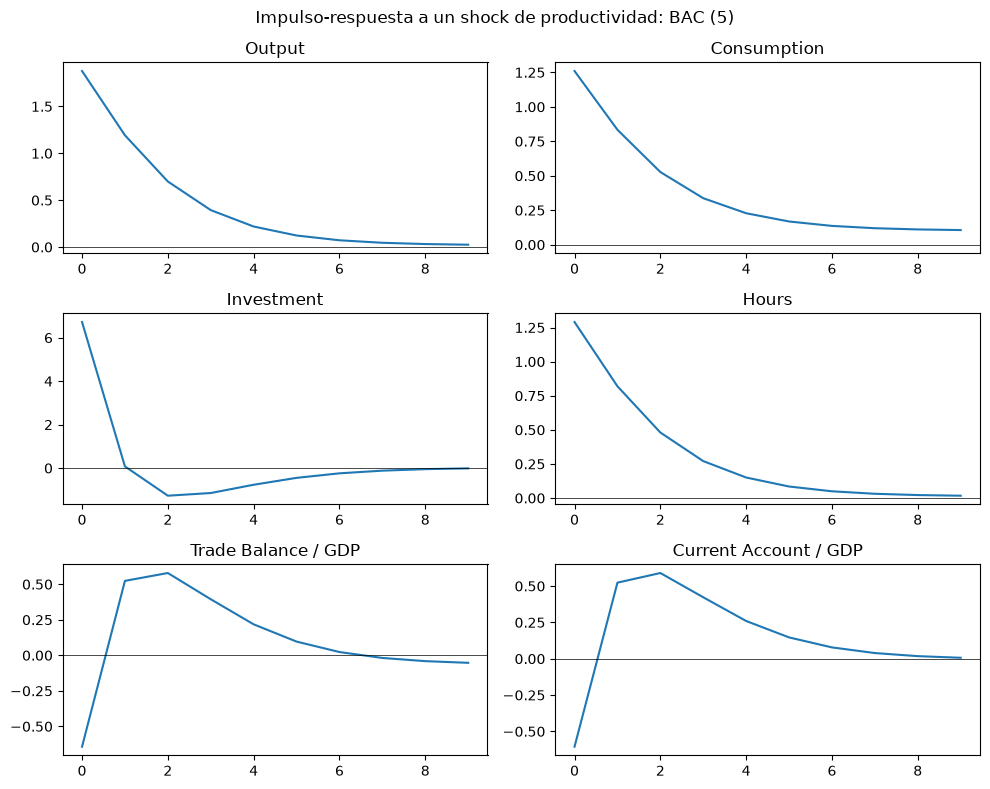

In [17]:
def bac_ss():
    return _open_econ_ss(0.11135 / 150)


def bac_model(approx=1):
    GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R, DBAR = sp.symbols('GAMA DELTA ALFA PSSI RHO OMEGA PHI R DBAR', real=True)
    S = _open_econ_symbols()
    c, k, kp, k1, k1p, a, ap, h, hp, d, dp = [S[n] for n in 'c k kp k1 k1p a ap h hp d dp'.split()]
    yy, iv, tb, la, lap, tby, cay = [S[n] for n in 'yy iv tb la lap tby cay'.split()]
    u = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    e1 = (1 + R) * d - sp.log(tb) - dp
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2 - PSSI / 2 * (DBAR - dp)**2
    e3 = -yy + a * k**ALFA * h**(1 - ALFA)
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la * (1 + PSSI * (DBAR - dp)) + lap
    e6 = -la + sp.diff(u, c)
    e7 = -sp.diff(u, h) - la * sp.diff(output, h)
    e8 = -la * (1 + PHI * (kp - k)) + 1 / (1 + R) * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e9 = -k1 + kp
    e10 = -sp.log(ap) + RHO * sp.log(a)
    e11 = -sp.log(tby) + sp.log(tb) / yy
    e12 = -sp.log(cay) - R * d / yy + sp.log(tby)
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12])
    return _finish_open_econ(S, [GAMA, DELTA, ALFA, PSSI, RHO, OMEGA, PHI, R, DBAR], f, approx)


d, f, symtab = bac_model()
nd = num_eval(d, f, make_values(bac_ss(), symtab))
res5 = run_mendoza(nd, 'BAC (5)')

## 9. Modelo 6: mercados de activos completos (`6. Complete Asset Markets Model`)
Estado $[s,k,a]$ con $s$ el valor del portafolio de activos contingentes; la utilidad marginal de la riqueza $\lambda$ es constante (condición de mercados completos con $\psi_{CAM}$ calibrado al estado estacionario del EDEIR).

exitflag = 1 | autovalores de hx: [0.    +0.j 0.4855+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.0655,0.6122,1.0000
c,1.9067,0.6122,1.0000
i,9.1002,0.0700,0.6581
tb/y,1.5791,0.3913,0.1282
ca/y,3.1310,-0.0691,-0.4923


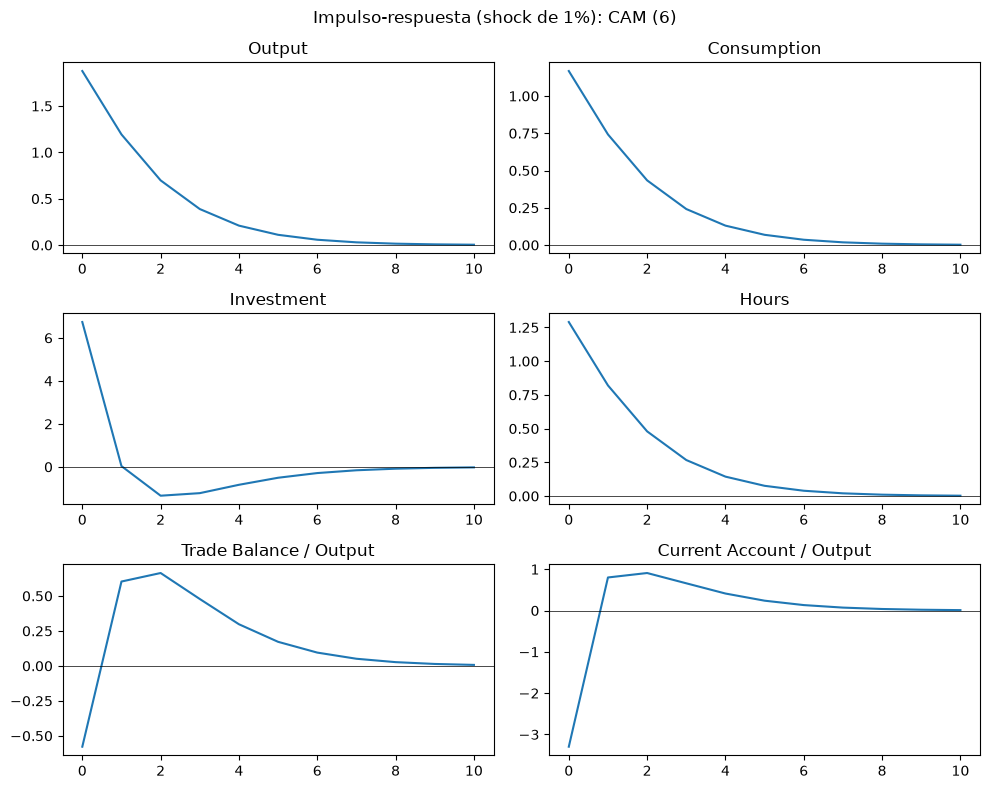

In [18]:
def cam_ss():
    SIGG = 2; DELTA = 0.1; RSTAR = 0.04; ALFA = 0.32; OMEGA = 1.455
    DBAR = 0.74421765717098; PHI = 0.028; RHO = 0.42; STD_EPS_A = 0.0129
    BETTA = 1 / (1 + RSTAR)
    KAPA = ((1 / BETTA - (1 - DELTA)) / ALFA) ** (1 / (ALFA - 1))
    h = ((1 - ALFA) * KAPA**ALFA) ** (1 / (OMEGA - 1))
    k = KAPA * h
    output = KAPA**ALFA * h
    c = output - DELTA * k - RSTAR * DBAR          # consumo del modelo EDEIR, usado para calibrar PSSI_CAM
    ivv = DELTA * k
    tb = output - ivv - c
    tby = tb / output
    ca = 0.0
    cay = ca / output
    s = tb * BETTA / (BETTA - 1)
    b = s / BETTA
    a = 1.0
    la = (c - h**OMEGA / OMEGA) ** (-SIGG)
    PSSI_CAM = la
    return dict(SIGG=SIGG, DELTA=DELTA, ALFA=ALFA, OMEGA=OMEGA, PHI=PHI, RHO=RHO, STD_EPS_A=STD_EPS_A, BETTA=BETTA,
                PSSI_CAM=PSSI_CAM, h=h, k=k, output=output, c=c, ivv=ivv, tb=tb, tby=tby, ca=ca, cay=cay, s=s, b=b,
                a=a, la=la, kfu=k)


def cam_model():
    BETTA, DELTA, ALFA, PHI, RHO, STD_EPS_A, SIGG, OMEGA, PSSI_CAM = sp.symbols(
        'BETTA DELTA ALFA PHI RHO STD_EPS_A SIGG OMEGA PSSI_CAM', real=True)
    names = 'c cp h hp k kp kfu kfup la lap tb tbp ca cap ivv ivvp tby tbyp cay cayp a ap output outputp s sp b bp'
    (c, cp, h, hp, k, kp, kfu, kfup, la, lap, tb, tbp, ca, cap, ivv, ivvp, tby, tbyp, cay, cayp,
     a, ap, output, outputp, s, sp_, b, bp) = sp.symbols(names, real=True)
    e1 = -la + PSSI_CAM
    e2 = -output + a * k**ALFA * h**(1 - ALFA)
    e3 = -la + (c - h**OMEGA / OMEGA) ** (-SIGG)
    e4 = -h**(OMEGA - 1) + (1 - ALFA) * a * (k / h)**ALFA
    e5 = -sp_ + BETTA * lap / la * bp
    e6 = -la * (1 + PHI * (kp - k)) + BETTA * lap * (1 - DELTA + ALFA * ap * (kp / hp)**(ALFA - 1) + PHI * (kfup - kp))
    e7 = -sp_ + b + tb
    e8 = -ivv + kp - (1 - DELTA) * k
    e9 = -tb + output - c - ivv
    e10 = -tby + tb / output
    e11 = -ca + sp_ - s
    e12 = -cay + ca / output
    e13 = -sp.log(ap) + RHO * sp.log(a)
    e14 = -kfu + kp
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12, e13, e14])

    states_in_logs, states_in_logsp = [k, a], [kp, ap]
    statevar, statevarp = [s] + states_in_logs, [sp_] + states_in_logsp
    controls_in_logs = [c, ivv, output, h, la, kfu]
    controls_in_logsp = [cp, ivvp, outputp, hp, lap, kfup]
    controlvar = controls_in_logs + [tb, tby, ca, cay, b]
    controlvarp = controls_in_logsp + [tbp, tbyp, cap, cayp, bp]
    variables_in_logs = states_in_logs + controls_in_logs + states_in_logsp + controls_in_logsp
    f = log_subs(f, variables_in_logs)
    dd = anal_deriv(f, statevar, controlvar, statevarp, controlvarp, 1)
    ns = len(statevar)
    ETASHOCK = sp.zeros(ns, 1); ETASHOCK[ns - 1] = STD_EPS_A
    symtab = {str(x_): x_ for x_ in (BETTA, DELTA, ALFA, PHI, RHO, STD_EPS_A, SIGG, OMEGA, PSSI_CAM,
              c, cp, h, hp, k, kp, kfu, kfup, la, lap, tb, tbp, ca, cap, ivv, ivvp, tby, tbyp, cay, cayp,
              a, ap, output, outputp, s, sp_, b, bp)}
    return anal_deriv_print2f(dd, f, symtab, extra={'ETASHOCK': _to_obj(ETASHOCK)})


def cam_values(ss):
    v = to_model_point(ss, log_names=['k', 'a', 'c', 'ivv', 'output', 'h', 'la', 'kfu'],
                       level_names=['s', 'b', 'tb', 'tby', 'ca', 'cay'])
    for n in ['SIGG', 'DELTA', 'ALFA', 'OMEGA', 'PHI', 'RHO', 'STD_EPS_A', 'BETTA', 'PSSI_CAM']:
        v[n] = ss[n]
    return v


cam_num_eval = cam_model()
nd = cam_num_eval(cam_values(cam_ss()))
gx, hx, exitflag = gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'])
nx = hx.shape[0]
print('exitflag =', exitflag, '| autovalores de hx:', np.round(np.linalg.eigvals(hx), 4))
varshock = nd['ETASHOCK'] @ nd['ETASHOCK'].T

# indices 0-based de controls: c, ivv, output, h, la, kfu, tb, tby, ca, cay, b
iout, ic, iivv, ih, itby, ica, icay = 2, 0, 1, 3, 7, 8, 9
np.seterr(invalid='ignore', divide='ignore')   # variables de varianza cero (p.ej. lambda constante) dan NaN en las razones, como en MATLAB
sigy0, sigx0 = mom(gx, hx, varshock)
stds = np.sqrt(np.diag(sigy0))
corr_xy = sigy0[:, iout] / stds[iout] / stds
sigy1, sigx1 = mom(gx, hx, varshock, 1)
scorr = np.diag(sigy1) / np.diag(sigy0)
tab6 = pd.DataFrame(np.column_stack([stds * 100, scorr, corr_xy])[[iout, ic, iivv, itby, icay]],
                    index=['y', 'c', 'i', 'tb/y', 'ca/y'], columns=['std (%)', 'autocorr.', 'corr con y'])
display(tab6)

T = 11
x0 = np.zeros(nx); x0[-1] = 0.01
IR, IRy, IRx = ir(gx, hx, x0, T)
t = np.arange(T)
fig, axs = plt.subplots(3, 2, figsize=(10, 8))
for ax, j, ttl in zip(axs.ravel(), [iout, ic, iivv, ih, itby, ica],
                      ['Output', 'Consumption', 'Investment', 'Hours', 'Trade Balance / Output', 'Current Account / Output']):
    ax.plot(t, IR[:, j] * 100); ax.set_title(ttl); ax.axhline(0, color='k', lw=.5)
fig.suptitle('Impulso-respuesta (shock de 1%): CAM (6)'); fig.tight_layout(); plt.show()

## 10. Modelo 7: caso no estacionario (`7. The Nonstationary Case`)
Con $\beta(1+R)=1$ y $\lambda_{t+1}=\lambda_t$ la utilidad marginal de la riqueza es un paseo aleatorio: $h_x$ tiene una raíz unitaria y el consumo
responde permanentemente. El `run` original solo calcula impulso–respuesta (no hay momentos incondicionales).
Con una raíz unitaria exacta, `gx_hx` con `stake=1` puede clasificarla como inestable por redondeo; se prueba con `stake=1` y con `stake=1+1e-6`.

In [19]:
def rw_ss():
    return _open_econ_ss(None)


def rw_model(approx=1):
    GAMA, DELTA, ALFA, RHO, OMEGA, PHI, R, DBAR = sp.symbols('GAMA DELTA ALFA RHO OMEGA PHI R DBAR', real=True)
    S = _open_econ_symbols()
    c, k, kp, k1, k1p, a, ap, h, hp, d, dp = [S[n] for n in 'c k kp k1 k1p a ap h hp d dp'.split()]
    yy, iv, tb, la, lap, tby, cay = [S[n] for n in 'yy iv tb la lap tby cay'.split()]
    u = ((c - h**OMEGA / OMEGA) ** (1 - GAMA) - 1) / (1 - GAMA)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    e1 = (1 + R) * d - sp.log(tb) - dp
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2
    e3 = -yy + a * k**ALFA * h**(1 - ALFA)
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la + lap
    e6 = -la + sp.diff(u, c)
    e7 = -sp.diff(u, h) - la * sp.diff(output, h)
    e8 = -la * (1 + PHI * (kp - k)) + 1 / (1 + R) * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e9 = -k1 + kp
    e10 = -sp.log(ap) + RHO * sp.log(a)
    e11 = -sp.log(tby) + sp.log(tb) / yy
    e12 = -sp.log(cay) - R * d / yy + sp.log(tby)
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12])
    return _finish_open_econ(S, [GAMA, DELTA, ALFA, RHO, OMEGA, PHI, R, DBAR], f, approx)


d, f, symtab = rw_model()
nd = num_eval(d, f, make_values(rw_ss(), symtab))
for stake in (1.0, 1 + 1e-6):
    gx_, hx_, flag_ = gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'], stake)
    print(f'stake = {stake}: exitflag = {flag_}; autovalores de hx =', np.round(np.linalg.eigvals(hx_), 6))

Advertencia: no existe equilibrio local
stake = 1.0: exitflag = 0; autovalores de hx = [0.42    +0.j 0.485537+0.j]
stake = 1.000001: exitflag = 1; autovalores de hx = [0.485537+0.j 1.      +0.j 0.42    +0.j]


Advertencia: no existe equilibrio local
Random walk (7): exitflag = 1; autovalores de hx = [0.4855+0.j 1.    +0.j 0.42  +0.j]


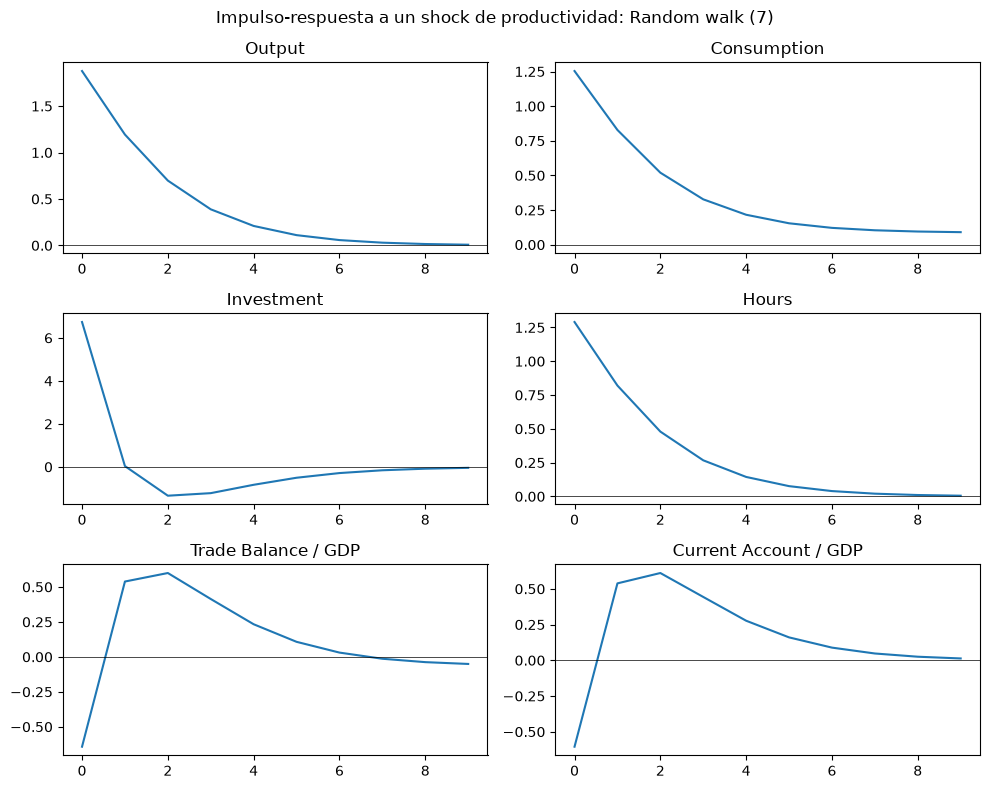

In [20]:
stake_ok = 1.0 if gx_hx(nd['fy'], nd['fx'], nd['fyp'], nd['fxp'], 1.0)[2] == 1 else 1 + 1e-6
res7 = run_mendoza(nd, 'Random walk (7)', moments=False, stake=stake_ok)

## 11. Modelo 8: juventud perpetua (`8. Perpetual Youth Model`)
Hogares con probabilidad de supervivencia $\theta=1-1/75$ y utilidad con punto de saciedad $\bar x$ (Blanchard–Yaari). El estado estacionario depende de $R$,
que se calibra para que la deuda de estado estacionario sea consistente con la restricción agregada (`find_interest_rate_ss.m`, que no está en la carpeta):
se vuelve a encontrar numéricamente y se compara con el valor 0.0374509 fijo en `py_ss.m`.

In [21]:
from scipy.optimize import minimize_scalar


def py_ss(R_input=0.0374509):
    DELTA = 0.1; ALFA = 0.32; RHO = 0.42; OMEGA = 1.455; PHI = 0.028
    R = R_input
    BETTA = 1 / 1.04
    SIGG = 2
    TBY = 0.02
    THETA = 1 - 1 / 75
    h_over_k = ((1 / BETTA - 1 + DELTA) / ALFA) ** (1 / (1 - ALFA))
    h = ((1 - ALFA) * h_over_k ** (-ALFA)) ** (1 / (OMEGA - 1))
    k = h / h_over_k
    iv = DELTA * k
    yy = k**ALFA * h**(1 - ALFA)
    d = TBY * yy / R
    tb = TBY * yy
    c = yy - tb - iv
    x = c - h**OMEGA / OMEGA
    XBAR = x * (1 + SIGG) / SIGG
    pai = ALFA * yy - iv
    zz = pai + (1 - 1 / OMEGA) * (1 - ALFA) * yy - XBAR
    zztil = THETA / (1 + R - THETA) * zz
    la = -(x - XBAR)
    tby = tb / yy
    cay = (-R * d + tb) / yy
    k1 = k
    a = 1.0
    cc = THETA * (1 - BETTA * (1 + R)) / ((1 + R - THETA) * (THETA - BETTA * (1 + R)))
    dist = abs(d - cc * zz)
    ss = dict(DELTA=DELTA, ALFA=ALFA, RHO=RHO, OMEGA=OMEGA, PHI=PHI, R=R, XBAR=XBAR, THETA=THETA, BETTA=BETTA,
              c=c, h=h, k=k, k1=k1, d=d, iv=iv, tb=tb, la=la, yy=yy, a=a, tby=tby, cay=cay, zztil=zztil)
    ss = log_ss(ss, ['c', 'h', 'k', 'k1', 'la', 'yy', 'iv', 'a'])           # d, tb, zztil, tby, cay en niveles
    for n in ['d', 'tb', 'zztil', 'tby', 'cay']:
        ss[n + 'p'] = ss[n]
    return ss, dist


def find_interest_rate_ss():
    # R tal que dist = |d - cc*zz| = 0 (en el original: find_interest_rate_ss.m)
    grid = np.linspace(0.0325, 0.0425, 201)
    i = int(np.argmin([py_ss(R)[1] for R in grid]))
    res = minimize_scalar(lambda R: py_ss(R)[1], bounds=(grid[max(i - 1, 0)], grid[min(i + 1, 200)]),
                          method='bounded', options={'xatol': 1e-13})
    return res.x, res.fun


R_star, dist_min = find_interest_rate_ss()
print(f'R que anula dist: {R_star:.7f} (dist = {dist_min:.2e});  valor de py_ss.m: 0.0374509 -> dist = {py_ss(0.0374509)[1]:.2e}')

R que anula dist: 0.0374509 (dist = 5.14e-08);  valor de py_ss.m: 0.0374509 -> dist = 4.68e-07


Perpetual Youth (8): exitflag = 1; autovalores de hx = [0.4545+0.j 0.9906+0.j 0.42  +0.j]


,std (%),autocorr.,corr con y
y,3.1082,0.6234,1.0000
c,2.4897,0.7410,0.9351
i,8.7350,0.0642,0.6928
h,2.1363,0.6234,1.0000
tb/y,1.4568,0.3414,-0.0594
ca/y,1.3492,0.2920,0.0388


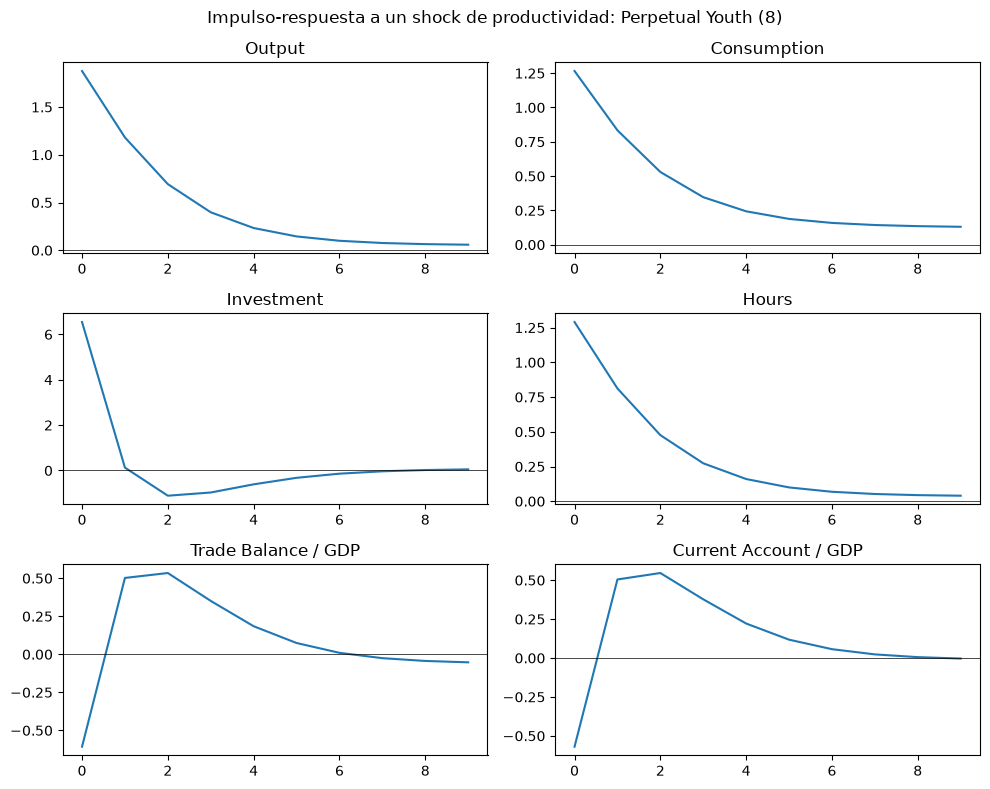

In [22]:
def py_model(approx=1):
    DELTA, ALFA, THETA, RHO, OMEGA, PHI, R, XBAR, BETTA = sp.symbols('DELTA ALFA THETA RHO OMEGA PHI R XBAR BETTA', real=True)
    names = 'c cp k kp k1 k1p a ap h hp d dp yy yyp iv ivp tb tbp la lap tby tbyp cay cayp zztil zztilp'
    (c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap, tby, tbyp, cay, cayp,
     zztil, zztilp) = sp.symbols(names, real=True)
    output = a * k**ALFA * h**(1 - ALFA)
    outputp = ap * kp**ALFA * hp**(1 - ALFA)
    pai = ALFA * output - iv - PHI / 2 * (kp - k)**2
    zz = pai + (1 - 1 / OMEGA) * (1 - ALFA) * output - XBAR
    xx = XBAR + (BETTA * (1 + R)**2 - THETA) / BETTA / THETA / (1 + R) * (sp.log(zztil) - THETA * sp.log(d))
    e1 = (1 + R) * sp.log(d) - zz + xx - XBAR - sp.log(dp)
    e2 = -sp.log(tb) + yy - c - iv - PHI / 2 * (kp - k)**2
    e3 = -yy + output
    e4 = -iv + kp - (1 - DELTA) * k
    e5 = -la - (xx - XBAR)
    e6 = -sp.diff(output, h) + h**(OMEGA - 1)
    e7 = -la * (1 + PHI * (kp - k)) + BETTA * lap * (sp.diff(outputp, kp) + 1 - DELTA + PHI * (k1p - k1))
    e8 = -k1 + kp
    e9 = -sp.log(ap) + RHO * sp.log(a)
    e10 = -sp.log(tby) + sp.log(tb) / yy
    e11 = -sp.log(cay) - (sp.log(dp) - sp.log(d)) / yy
    e12 = -sp.log(zztil) + THETA / (1 + R) * (zz + sp.log(zztilp))
    e13 = -xx + c - h**OMEGA / OMEGA
    f = sp.Matrix([e1, e2, e3, e4, e5, e6, e7, e8, e9, e10, e11, e12, e13])
    x = [k, d, a]
    y = [yy, c, iv, h, tby, cay, tb, la, k1, zztil]
    xp = [kp, dp, ap]
    yp = [yyp, cp, ivp, hp, tbyp, cayp, tbp, lap, k1p, zztilp]
    f = log_subs(f, x + y + xp + yp)
    dd = anal_deriv(f, x, y, xp, yp, approx)
    symtab = {str(s): s for s in (DELTA, ALFA, THETA, RHO, OMEGA, PHI, R, XBAR, BETTA,
              c, cp, k, kp, k1, k1p, a, ap, h, hp, d, dp, yy, yyp, iv, ivp, tb, tbp, la, lap, tby, tbyp, cay, cayp, zztil, zztilp)}
    return dd, f, symtab


d, f, symtab = py_model()
ss_py, dist = py_ss()
nd = num_eval(d, f, make_values(ss_py, symtab))
res8 = run_mendoza(nd, 'Perpetual Youth (8)')